[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/14_material_discrimination_target_detection.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🎯 Material Discrimination & Target Detection
### Space Academy 2026 · Hyperspectral course · Week 2 — Material discrimination and target detection (Lecture + Practical)

A multispectral sensor can tell you that a pixel is *bright* or *green*. A hyperspectral sensor can often tell you
**what it is made of**, and sometimes whether a material you are looking for is hiding **inside** a 30 m pixel that is
mostly something else. This notebook covers the three families of methods that make that possible:

| Family | Question it answers | Typical methods |
|---|---|---|
| **Spectral similarity** | *Which reference material does this whole pixel look most like?* | SAM, SID, continuum-removed feature matching |
| **Target detection** | *Is a small amount of material X present in this pixel?* | Matched filter (MF), ACE, CEM |
| **Spectral unmixing** | *What fraction of the pixel is each material?* | Endmember extraction (N-FINDR, VCA, PPI) + NNLS / FCLS |

**What you will learn**
- How the spectral angle (SAM) and spectral information divergence (SID) work, and why SAM ignores illumination
- How to build rule images, choose thresholds and make a SAM classification map
- How continuum removal isolates diagnostic absorption features (clay minerals in coal-mine spoil)
- The maths behind the matched filter, ACE and CEM, and why they beat SAM for **sub-pixel** targets
- How to benchmark detectors honestly with a **target-implantation** experiment and ROC curves
- How to extract endmembers with N-FINDR and estimate abundances with NNLS and fully constrained least squares
- Why methane mapping uses a matched filter, and why simple band ratios are only a proxy

**Prerequisites:** notebook `10_spectral_signatures_and_libraries` (reference library) and `11_preprocessing`
(bad bands, masks). Notebook `13_feature_extraction_dim_reduction` (PCA) helps for section 4.

**Data** — three Tanager scenes (`hu.get_scene()` uses the local HDF5 or downloads ~1 GB from Planet's STAC catalogue):

| Scene | Place | Used for |
|---|---|---|
| `20250219_053251_31_4001` | Kusmunda coal mine, Korba, India | SAM/SID classification, clay feature mapping |
| `20250407_035509_25_4001` | Ho Chi Minh City, Vietnam | Target detection of blue industrial roofs |
| `20250223_165546_32_4001` | Jiquilisco Bay, El Salvador | Spectral unmixing |

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import nnls
from sklearn.metrics import roc_curve, roc_auc_score
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

## 1. The reference library

Every method in this notebook compares image spectra with **reference spectra**. We use the course library built in
notebook 10: median spectra of homogeneous, WorldCover-verified areas in the course scenes. Image-derived references
have one big advantage over laboratory spectra: they were measured by the *same sensor*, under real atmospheric
correction, at the *same 30 m scale*. Their disadvantage: a "pure" 30 m pixel of *dense urban* is itself a mixture.

The library spectra carry `NaN` in the removed bands (water vapour, SWIR edge). Because each scene has slightly
different band centres, the helper below interpolates the library onto the scene's wavelengths and returns the
bands where **all** references are valid.

In [2]:
lib_wl, lib, lib_meta = hu.load_library()
print(f"{len(lib)} reference spectra, {np.isfinite(lib['mangrove']).sum()} valid bands each")
print(pd.DataFrame(lib_meta)[["name", "place", "n_pixels_used"]].to_string(index=False))


def library_on(wl, names):
    # Interpolate the chosen library spectra onto a scene's wavelength grid.
    # Returns R (n_refs, n_bands) and a boolean mask of bands where every reference is finite.
    R = np.array([np.interp(wl, lib_wl, lib[n]) for n in names])
    ok = np.all(np.isfinite(R), axis=0)
    return R, ok

19 reference spectra, 354 valid bands each
                  name                      place  n_pixels_used
              mangrove      Usulután, El Salvador            400
   tropical_tree_cover      Usulután, El Salvador            400
    sugarcane_cropland      Usulután, El Salvador            400
  turbid_estuary_water      Usulután, El Salvador            400
            sand_beach      Usulután, El Salvador             89
        irrigated_crop             Konya, Türkiye            400
         dry_bare_soil             Konya, Türkiye            400
  dry_steppe_grassland             Konya, Türkiye            400
           dense_urban  Ho Chi Minh City, Vietnam            400
bright_industrial_roof  Ho Chi Minh City, Vietnam            400
           river_water  Ho Chi Minh City, Vietnam            400
    chaparral_unburned    Malibu, California, USA            400
             burn_scar    Malibu, California, USA            400
           clear_ocean    Malibu, California, U

## 2. Spectral similarity measures

### 2.1 Three ways to compare two spectra

For a pixel spectrum $\mathbf{x}$ and a reference $\mathbf{r}$ (both vectors of $B$ band values):

- **Euclidean distance** $\;d_E = \lVert \mathbf{x} - \mathbf{r} \rVert_2\;$ — sensitive to brightness *and* shape.
- **Spectral Angle Mapper (SAM)** (Kruse et al., 1993) treats spectra as vectors in $B$-dimensional space and measures
  the angle between them:
  $$\alpha = \arccos\left(\frac{\mathbf{x}\cdot\mathbf{r}}{\lVert\mathbf{x}\rVert\,\lVert\mathbf{r}\rVert}\right)$$
  Multiplying a spectrum by a constant (a shadowed slope, a darker day) does **not** change the angle — SAM compares
  *shape only*.
- **Spectral Information Divergence (SID)** (Chang, 2000) turns each spectrum into a probability distribution
  $p_b = x_b / \sum x$, $q_b = r_b / \sum r$ and measures the symmetric Kullback–Leibler divergence
  $$\mathrm{SID} = \sum_b p_b \log\frac{p_b}{q_b} + \sum_b q_b \log\frac{q_b}{p_b}$$
  It is also brightness-invariant, but weighs differences in *where* the spectrum's energy is concentrated.

Let us check the brightness invariance on a real spectrum.

In [3]:
def sid(X, ref, eps=1e-6):
    # Spectral information divergence between each row of X (n, bands) and ref (bands,).
    X = np.clip(np.atleast_2d(X), eps, None)
    r = np.clip(ref, eps, None)
    P = X / X.sum(axis=1, keepdims=True)
    q = r / r.sum()
    return np.sum(P * np.log(P / q), axis=1) + np.sum(q * np.log(q / P), axis=1)


ok = np.isfinite(lib["dry_bare_soil"])
soil = lib["dry_bare_soil"][ok]
shadowed_soil = 0.5 * soil                      # same material, half the illumination
steppe = lib["dry_steppe_grassland"][ok]        # a different, but similar-looking material

rows = []
for name, s in [("same soil, 50 % illumination", shadowed_soil), ("dry steppe grassland", steppe)]:
    rows.append(dict(comparison=f"dry bare soil vs {name}",
                     euclidean=np.linalg.norm(soil - s),
                     SAM_rad=hu.spectral_angle(s[None], soil)[0],
                     SID=sid(s[None], soil)[0]))
pd.DataFrame(rows).round(4)

,comparison,euclidean,SAM_rad,SID
0,"dry bare soil vs same soil, 50 % illumination",3.8370,0.0000,0.0000
1,dry bare soil vs dry steppe grassland,0.9484,0.0836,0.0104


The Euclidean distance says the *shadowed soil* is far more different from the soil than the grassland is — while SAM
and SID correctly report that the shadowed soil has an **identical shape** (distance 0). That is why angle-based
measures are the default for material matching.

### 2.2 Which library materials are easy or hard to tell apart?

A SAM matrix between all library entries shows which pairs are spectrally close. Small angles (dark cells) mean the
materials will be confused by any whole-pixel method.

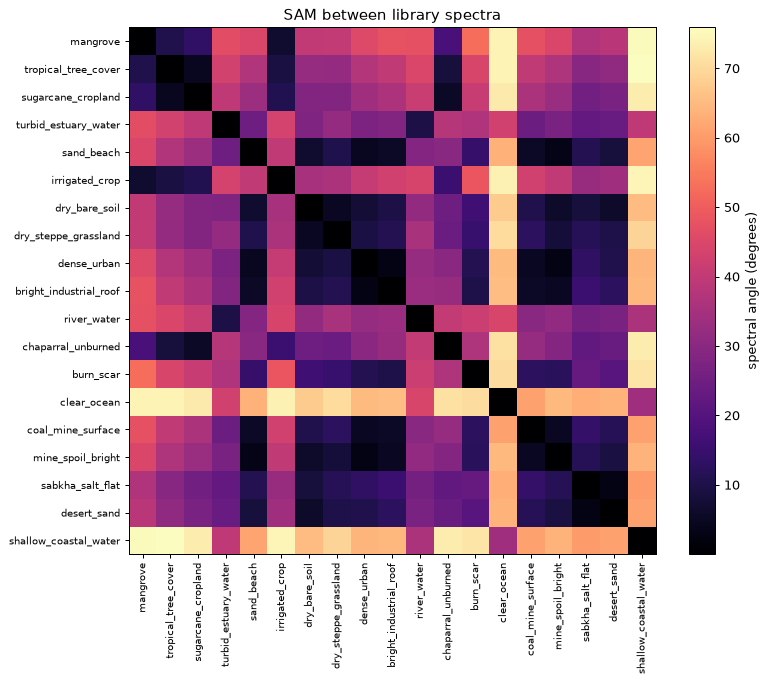

Five most similar pairs:
   2.83°  dense_urban  ↔  bright_industrial_roof
   2.83°  dense_urban  ↔  mine_spoil_bright
   2.91°  sabkha_salt_flat  ↔  desert_sand
   3.55°  sand_beach  ↔  mine_spoil_bright
   4.45°  tropical_tree_cover  ↔  sugarcane_cropland


In [4]:
names = list(lib)
ok = np.all([np.isfinite(lib[n]) for n in names], axis=0)
L = np.array([lib[n][ok] for n in names])
sam_matrix = np.array([hu.spectral_angle(L, L[i]) for i in range(len(names))])

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(np.degrees(sam_matrix), cmap="magma")
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=8)
ax.set_yticks(range(len(names)), names, fontsize=8)
plt.colorbar(im, ax=ax, label="spectral angle (degrees)")
ax.set_title("SAM between library spectra")
plt.tight_layout(); plt.show()

pairs = [(sam_matrix[i, j], names[i], names[j]) for i in range(len(names)) for j in range(i + 1, len(names))]
print("Five most similar pairs:")
for a, n1, n2 in sorted(pairs)[:5]:
    print(f"  {np.degrees(a):5.2f}°  {n1}  ↔  {n2}")

Pairs only a few degrees apart — bright urban surfaces vs mine spoil, sabkha vs desert sand, or the green vegetation
types among each other — are hard to separate from spectral shape alone. Expect them to be confused in
classification (notebook 15) and to need extra information: texture, context (distance to the coast, to a mine),
or time series.

### 2.3 SAM classification of the Kusmunda coal mine

Kusmunda (Korba coalfield) is one of the largest open-cast coal mines in Asia. The window below contains dark coal
faces, bright spoil (overburden) dumps, water in the pits, dry farmland and trees.

A SAM classification has three steps:
1. **Rule images** — one angle map per reference material.
2. **Minimum-angle rule** — assign each pixel to the reference with the smallest angle.
3. **Threshold** — if even the best angle is too large, label the pixel *unclassified* (the material is not in the
   library, or the pixel is a mixture).

window 180×540 px, 97200 complete spectra, 350 common bands


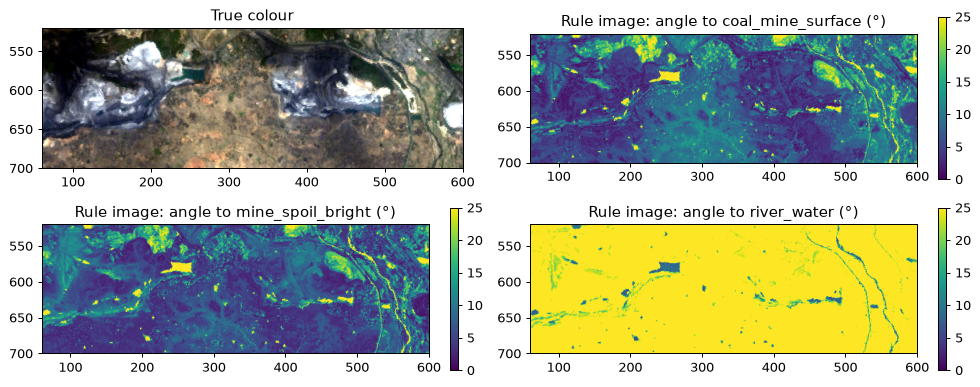

In [5]:
korba = hu.get_scene("20250219_053251_31_4001")
KW = (520, 700, 60, 600)                          # (row_start, row_stop, col_start, col_stop)
k_cube, k_wl = korba.read_cube(KW)
k_ext = (KW[2], KW[3], KW[1], KW[0])              # extent so axes show scene pixel coordinates

korba_refs = ["coal_mine_surface", "mine_spoil_bright", "river_water", "tropical_tree_cover",
              "dry_steppe_grassland", "dry_bare_soil", "dense_urban"]
R, ok = library_on(k_wl, korba_refs)
Xk, k_mask = hu.cube_to_pixels(k_cube[ok])
print(f"window {k_cube.shape[1]}×{k_cube.shape[2]} px, {Xk.shape[0]} complete spectra, {ok.sum()} common bands")

rule = np.stack([hu.spectral_angle(Xk, r) for r in R[:, ok]], axis=1)   # (pixels, refs) in radians

fig, axes = plt.subplots(2, 2, figsize=(11, 4.4))
axes[0, 0].imshow(hu.rgb_from_cube(k_cube, k_wl), extent=k_ext)
axes[0, 0].set_title("True colour")
for ax, i in zip(axes.flat[1:], [0, 1, 2]):
    im = ax.imshow(hu.pixels_to_image(np.degrees(rule[:, i]), k_mask), cmap="viridis", vmin=0, vmax=25,
                   extent=k_ext)
    ax.set_title(f"Rule image: angle to {korba_refs[i]} (°)")
    plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); plt.show()

In a rule image **dark = similar**. The coal rule image picks out the dark pit floors; the spoil rule image the bright
dumps. Now the minimum-angle classification. How do we pick the threshold? Look at the distribution of the *best*
angle per pixel: pixels whose best match is still far away are materials that are not in our library.

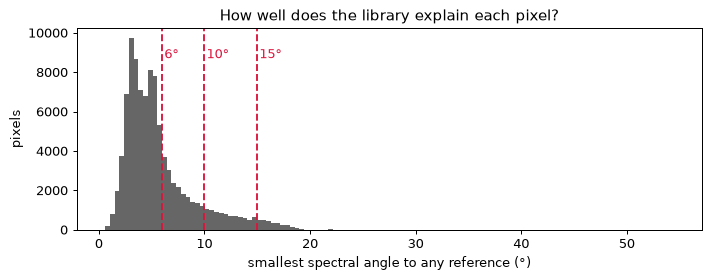

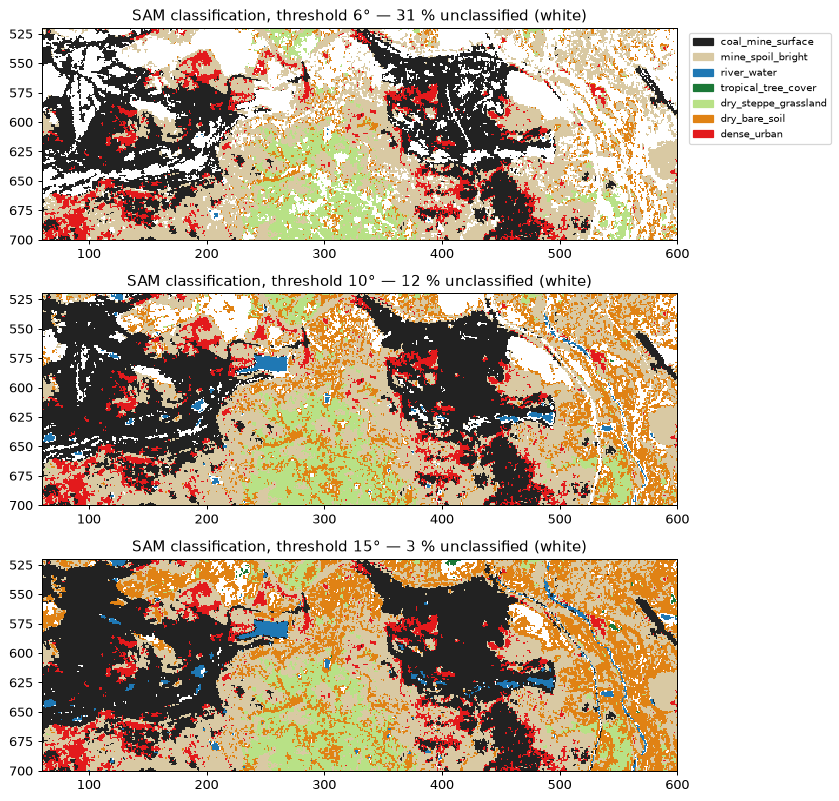

In [6]:
best = rule.min(axis=1)
best_class = rule.argmin(axis=1)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(np.degrees(best), bins=120, color="0.4")
for t in (6, 10, 15):
    ax.axvline(t, color="crimson", ls="--")
    ax.text(t + 0.2, ax.get_ylim()[1] * 0.85, f"{t}°", color="crimson")
ax.set_xlabel("smallest spectral angle to any reference (°)"); ax.set_ylabel("pixels")
ax.set_title("How well does the library explain each pixel?")
plt.tight_layout(); plt.show()

colors = ["#222222", "#d9c9a3", "#1f78b4", "#1b7837", "#b8e186", "#e08214", "#e31a1c"]
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
cmap = ListedColormap(colors); cmap.set_bad("white")

fig, axes = plt.subplots(3, 1, figsize=(11, 9))
for ax, t in zip(axes, (6, 10, 15)):
    cls = best_class.astype(float)
    cls[np.degrees(best) > t] = np.nan
    ax.imshow(hu.pixels_to_image(cls, k_mask), cmap=cmap, vmin=-0.5, vmax=len(colors) - 0.5,
              interpolation="nearest", extent=k_ext)
    ax.set_title(f"SAM classification, threshold {t}° — {np.mean(np.degrees(best) > t) * 100:.0f} % unclassified (white)")
axes[0].legend(handles=[Patch(color=c, label=n) for c, n in zip(colors, korba_refs)],
               loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.show()

A tight threshold leaves most of the scene unclassified: the references come from *other* scenes (except coal and
spoil), and at 30 m most pixels are mixtures. A loose threshold labels everything but forces unknown materials into
the wrong class. Good practice:

- choose thresholds **per class** from the rule-image histograms of known examples (exercise 1),
- report the unclassified fraction,
- where possible use **scene-derived** references (as we do for coal and spoil).

### 2.4 SID vs SAM

Do the two measures agree? We classify again with SID and count the pixels where both give the same class.

In [7]:
sid_rule = np.stack([sid(Xk, r) for r in R[:, ok]], axis=1)
sid_class = sid_rule.argmin(axis=1)
agree = (sid_class == best_class).mean()
print(f"SAM and SID assign the same class to {agree * 100:.1f} % of pixels")
short = np.array(["coal", "spoil", "water", "trees", "steppe", "soil", "urban"])
ct = pd.crosstab(pd.Series(short[best_class], name="SAM ↓ / SID →"), pd.Series(short[sid_class], name=""),
                 normalize="index") * 100
ct.round(1)   # % of each SAM class that SID puts in each class

SAM and SID assign the same class to 83.9 % of pixels


,coal,soil,spoil,steppe,trees,urban,water
SAM ↓ / SID →,,,,,,,
coal,99.5,0.0,0.0,0.0,0.0,0.4,0.1
soil,1.0,69.6,28.9,0.0,0.0,0.0,0.5
spoil,2.7,0.0,95.4,0.0,0.0,1.9,0.0
steppe,0.0,55.9,33.4,10.7,0.0,0.0,0.0
trees,0.0,73.9,0.0,0.0,23.6,0.0,2.5
urban,0.3,0.0,0.0,0.0,0.0,99.6,0.0
water,1.0,0.0,0.0,0.0,0.0,0.0,99.0


The two measures agree for most pixels; the disagreements are between spectrally similar classes (soil ↔ spoil,
steppe ↔ soil/spoil). SID is more sensitive in spectral regions where a material has little energy, SAM treats every band's
contribution through the dot product. In practice, test both on your own validation data.

### 2.5 Continuum removal: matching diagnostic absorption features

Whole-spectrum SAM is dominated by the broad shape of the spectrum (brightness slope, vegetation red edge).
Geologists usually match **specific absorption features** instead. *Continuum removal* (Clark & Roush, 1984) divides
the spectrum by its upper convex hull so that absorption features become dips below 1.0 whose depth can be compared
between bright and dark materials.

The clay minerals in weathered shale and sandstone have an **Al–OH absorption near 2200 nm**; kaolinite shows a
characteristic *doublet* at ~2165 and ~2205 nm.

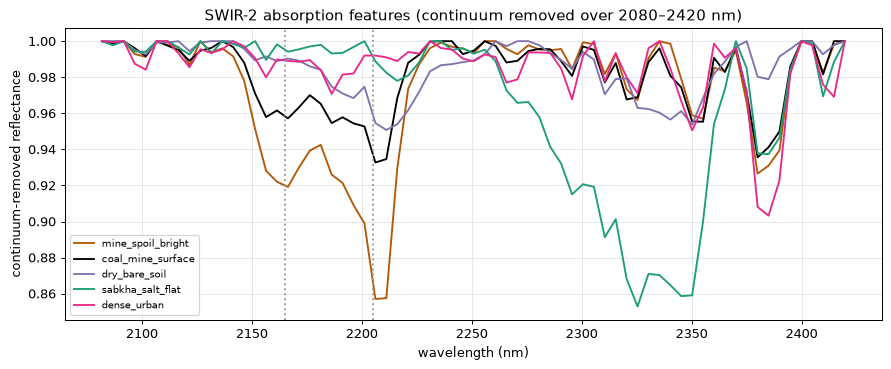

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sel = (lib_wl >= 2080) & (lib_wl <= 2420)
for n, c in [("mine_spoil_bright", "#b35806"), ("coal_mine_surface", "k"), ("dry_bare_soil", "#8073ac"),
             ("sabkha_salt_flat", "#1b9e77"), ("dense_urban", "#e7298a")]:
    s = lib[n][sel]
    good = np.isfinite(s)
    ax.plot(lib_wl[sel][good], hu.continuum_removed(lib_wl[sel][good], s[good]), label=n, color=c)
for x in (2165, 2205):
    ax.axvline(x, color="0.6", ls=":")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("continuum-removed reflectance")
ax.set_title("SWIR-2 absorption features (continuum removed over 2080–2420 nm)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The bright mine spoil shows the kaolinite-like doublet at 2165/2205 nm; the sabkha instead has its deepest feature
around 2330 nm (carbonate / sulphate minerals). We can map the depth of the 2205 nm feature — the continuum is the
straight line between shoulders at 2120 and 2250 nm (`hu.band_depth`) — and match the *continuum-removed feature
shape* against the spoil reference with SAM restricted to 2120–2250 nm.

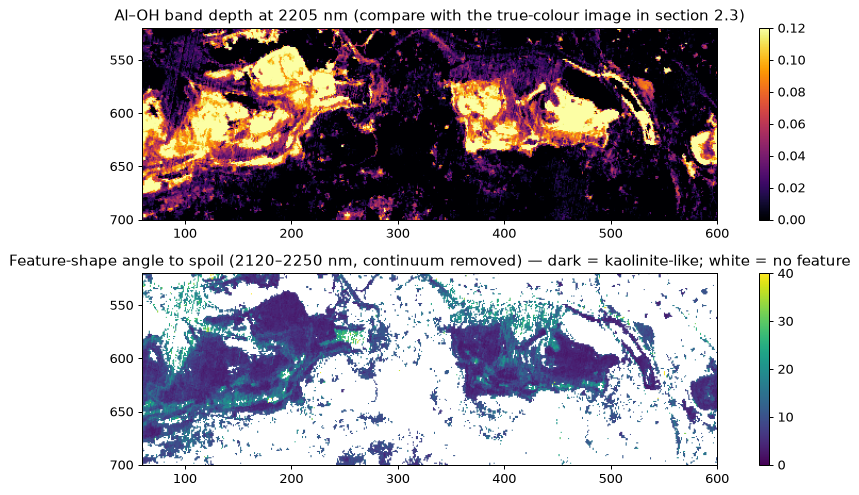

In [9]:
depth_2205 = hu.band_depth(k_wl, k_cube, 2120, 2205, 2250)

feat = (k_wl >= 2120) & (k_wl <= 2250)
def cr_window(spectra):
    # continuum-remove each spectrum (rows) over the feature window
    return np.array([hu.continuum_removed(k_wl[feat], s) for s in spectra])

Xf, f_mask = hu.cube_to_pixels(k_cube[feat])
ref_f = cr_window(np.interp(k_wl[feat], lib_wl, lib["mine_spoil_bright"])[None])[0]
Xf_cr = cr_window(Xf)
feature_angle = hu.spectral_angle(Xf_cr - 1, ref_f - 1)   # compare the *dips* (1 − CR) rather than the flat hull

angle_img = hu.pixels_to_image(np.degrees(feature_angle), f_mask)
angle_img[~(depth_2205 > 0.02)] = np.nan       # only where there is a feature to compare

fig, (ax_depth, ax_shape) = plt.subplots(2, 1, figsize=(10, 5.6))
im = ax_depth.imshow(depth_2205, cmap="inferno", vmin=0, vmax=0.12, extent=k_ext)
ax_depth.set_title("Al–OH band depth at 2205 nm (compare with the true-colour image in section 2.3)")
plt.colorbar(im, ax=ax_depth, fraction=0.02)
im = ax_shape.imshow(angle_img, cmap="viridis", vmin=0, vmax=40, extent=k_ext)
ax_shape.set_title("Feature-shape angle to spoil (2120–2250 nm, continuum removed) — dark = kaolinite-like; white = no feature")
plt.colorbar(im, ax=ax_shape, fraction=0.02)
plt.tight_layout(); plt.show()

Feature mapping highlights the spoil heaps *and* the mine benches where clay-bearing rock is exposed, independent of
how bright the pixel is; within those areas the feature *shape* tells kaolinite-like doublets (dark) from other
Al–OH or mixed features (lighter). This is exactly how mineral maps from AVIRIS, EnMAP and EMIT are made (e.g. the USGS
Tetracorder approach), just with more features and a mineral library.

⚠️ Always check features against **residual atmospheric absorption**: CO₂ at ~2010 and ~2060 nm and water vapour
around 1900 nm can leave artefacts that look like mineral features.

---
## 3. Target detection

> **Core versus deep dive.** The *core* of this section is one idea you can apply immediately: a detector asks
> "how much does this pixel look like my target, given what the rest of the scene looks like?", and it suppresses
> the background using the scene's own statistics. Run it, choose a threshold, look at the map — that is enough to
> use it in your project.
>
> The *deep dive* is the covariance mathematics (inversion, shrinkage, condition numbers) and the ROC analysis of
> the implantation experiment further down. Those matter when a detector misbehaves and you must explain why.
> If time is short, read the plots and come back to the algebra later.


### 3.1 Why similarity measures fail for small targets

SAM compares the *whole* pixel with the reference. If a target covers only 10 % of a 30 m pixel, 90 % of the signal
is background and the angle to the target stays large. **Detectors** instead model the background statistically and
look for the *direction* in spectral space in which the target pushes a pixel away from the background.

With background mean $\boldsymbol\mu$, background covariance $\boldsymbol\Sigma$, target signature $\mathbf{t}$ and
$\mathbf{s}=\mathbf{t}-\boldsymbol\mu$:

| Detector | Score for pixel $\mathbf{x}$ | Notes |
|---|---|---|
| **Matched filter (MF)** | $\dfrac{\mathbf{s}^\top\boldsymbol\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)}{\mathbf{s}^\top\boldsymbol\Sigma^{-1}\mathbf{s}}$ | ≈ target fraction for a linear mixture; optimal for Gaussian background |
| **ACE** (Kraut & Scharf, 1999) | $\dfrac{(\mathbf{s}^\top\boldsymbol\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu))^2}{(\mathbf{s}^\top\boldsymbol\Sigma^{-1}\mathbf{s})\,((\mathbf{x}-\boldsymbol\mu)^\top\boldsymbol\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu))}$ | = cos² of the *whitened* angle; scale-invariant, range 0–1 |
| **CEM** (Harsanyi, 1993) | $\mathbf{w}^\top\mathbf{x},\;\mathbf{w}=\dfrac{\mathbf{R}^{-1}\mathbf{t}}{\mathbf{t}^\top\mathbf{R}^{-1}\mathbf{t}}$ | $\mathbf{R}$ = correlation matrix of all pixels; minimises output energy while passing $\mathbf{t}$ with gain 1 |

The key ingredient is $\boldsymbol\Sigma^{-1}$: it **whitens** the background, suppressing the directions in which
the background naturally varies (vegetation amount, brightness) and amplifying directions the background rarely
visits. Manolakis & Shaw (2002) give an excellent overview.

**Covariance shrinkage.** With 350 correlated bands, $\boldsymbol\Sigma$ has tiny eigenvalues (mostly noise) and
its inverse amplifies them. We regularise with
$$\boldsymbol\Sigma_\lambda = (1-\lambda)\,\boldsymbol\Sigma + \lambda\,\frac{\mathrm{tr}(\boldsymbol\Sigma)}{B}\,\mathbf{I}.$$

### 3.2 The target: blue metal roofs in Ho Chi Minh City

The industrial parks south-west of Ho Chi Minh City have large blue-painted metal roofs. Two parks are in our window.
We take the signature from **park A only** and see whether the detectors find **park B**.

⚠️ The Tanager beta cloud mask flags several bright roofs in this window as cloud (a false positive — the scene is
clear). For this analysis we read the data with `cloud=False`.

cloud-flagged pixels in this clear window: 1.5 %


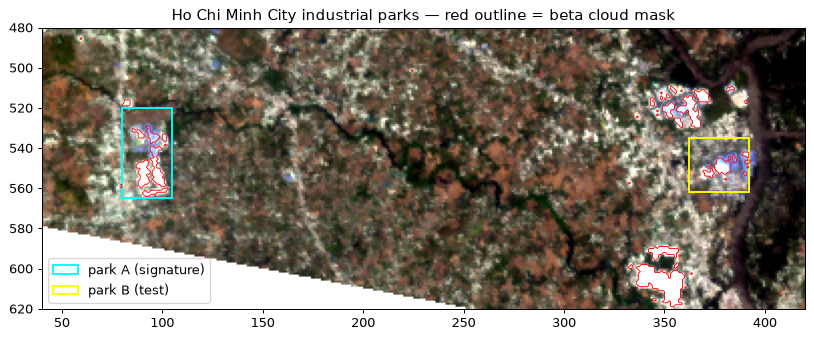

In [10]:
hcmc = hu.get_scene("20250407_035509_25_4001")
HW = (480, 620, 40, 420)
h_cube, h_wl = hcmc.read_cube(HW, cloud=False)
h_ext = (HW[2], HW[3], HW[1], HW[0])
cloud_flag = hcmc.masks(HW)["cloud"]
print(f"cloud-flagged pixels in this clear window: {cloud_flag.mean() * 100:.1f} %")

PARK_A = (520, 565, 80, 105)       # (r0, r1, c0, c1) in scene pixel coordinates
PARK_B = (535, 562, 362, 392)

def box_patch(b, color, label):
    from matplotlib.patches import Rectangle
    return Rectangle((b[2], b[0]), b[3] - b[2], b[1] - b[0], fill=False, ec=color, lw=1.5, label=label)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.imshow(hu.rgb_from_cube(h_cube, h_wl), extent=h_ext)
ax.contour(np.arange(HW[2], HW[3]) + 0.5, np.arange(HW[0], HW[1]) + 0.5, cloud_flag, levels=[0.5],
           colors="red", linewidths=0.7)
ax.add_patch(box_patch(PARK_A, "cyan", "park A (signature)"))
ax.add_patch(box_patch(PARK_B, "yellow", "park B (test)"))
ax.legend(loc="lower left"); ax.set_title("Ho Chi Minh City industrial parks — red outline = beta cloud mask")
plt.tight_layout(); plt.show()

Blue roofs reflect relatively more blue than red light. Inside park A we select the 10 % of pixels with the highest
blue/red ratio as target pixels, and split them randomly in two halves: **half 1** gives the detector signature
(median spectrum), **half 2** is used later to implant *realistic, slightly different* target spectra.

113 target pixels in park A → 56 for the signature, 57 for implanting


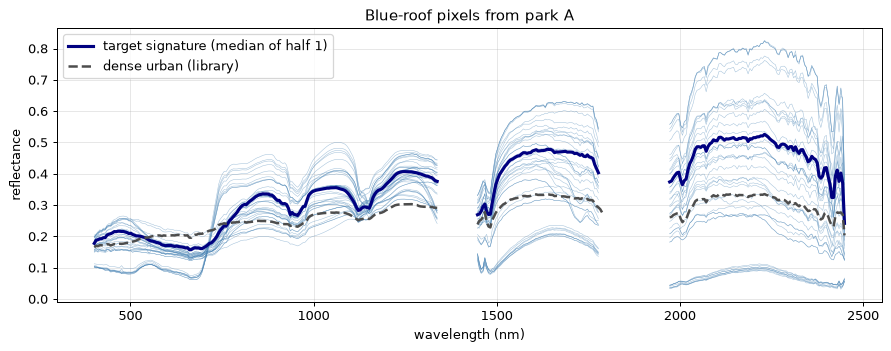

In [11]:
b = lambda nm: h_cube[hu.band_index(h_wl, nm)]
blue_red = b(480) / b(660)

r0, r1, c0, c1 = [PARK_A[0] - HW[0], PARK_A[1] - HW[0], PARK_A[2] - HW[2], PARK_A[3] - HW[2]]
sub = blue_red[r0:r1, c0:c1]
rr, cc = np.nonzero(sub >= np.nanpercentile(sub, 90))
target_pixels = h_cube[:, rr + r0, cc + c0].T                         # (n, bands)

rng = np.random.default_rng(7)
perm = rng.permutation(len(target_pixels))
half1, half2 = target_pixels[perm[: len(perm) // 2]], target_pixels[perm[len(perm) // 2:]]
t_sig = np.median(half1, axis=0)
print(f"{len(target_pixels)} target pixels in park A → {len(half1)} for the signature, {len(half2)} for implanting")

fig, ax = plt.subplots(figsize=(10, 4))
for s in target_pixels[:40]:
    hu.plot_spectrum(ax, h_wl, s, color="steelblue", lw=0.4, alpha=0.5)
hu.plot_spectrum(ax, h_wl, t_sig, color="navy", lw=2.5, label="target signature (median of half 1)")
hu.plot_spectrum(ax, lib_wl, lib["dense_urban"], color="0.3", lw=2, ls="--", label="dense urban (library)")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Blue-roof pixels from park A")
plt.tight_layout(); plt.show()

Note that even the "purest" roof pixels are mixtures at 30 m (the vegetation red edge is visible). That is fine —
the detector looks for the *direction* this signature adds to the background.

### 3.3 Background statistics
We estimate $\boldsymbol\mu$ and $\boldsymbol\Sigma$ from all window pixels **outside** both parks (in operational
use you would take the whole scene, assuming targets are rare). Look at the condition number before and after
shrinkage.

In [12]:
Xh, h_mask = hu.cube_to_pixels(h_cube)
rows, cols = np.nonzero(h_mask)
rows, cols = rows + HW[0], cols + HW[2]
def in_box(b):
    return (rows >= b[0]) & (rows < b[1]) & (cols >= b[2]) & (cols < b[3])
background = Xh[~(in_box(PARK_A) | in_box(PARK_B))]


def shrink(C, lam):
    p = C.shape[0]
    return (1 - lam) * C + lam * np.trace(C) / p * np.eye(p)


def background_stats(B, lam=1e-3):
    mu = B.mean(axis=0)
    C = np.cov(B, rowvar=False)
    return mu, np.linalg.inv(shrink(C, lam))


def matched_filter(X, t, mu, Ci):
    s = t - mu
    return ((X - mu) @ Ci @ s) / (s @ Ci @ s)


def ace(X, t, mu, Ci):
    s = t - mu
    Xc = X - mu
    return (Xc @ Ci @ s) ** 2 / ((s @ Ci @ s) * np.einsum("ij,ij->i", Xc @ Ci, Xc))


def cem(X, t, lam=1e-3, R_pixels=None):
    Rp = X if R_pixels is None else R_pixels
    Rinv = np.linalg.inv(shrink(Rp.T @ Rp / len(Rp), lam))
    w = Rinv @ t / (t @ Rinv @ t)
    return X @ w


C = np.cov(background, rowvar=False)
for lam in (0, 1e-4, 1e-3, 1e-2):
    print(f"λ = {lam:<6}: condition number of Σ = {np.linalg.cond(shrink(C, lam)):.2e}")

λ = 0     : condition number of Σ = 1.62e+11
λ = 0.0001: condition number of Σ = 2.79e+06
λ = 0.001 : condition number of Σ = 2.78e+05
λ = 0.01  : condition number of Σ = 2.76e+04


### 3.4 How good are the detectors? A target-implantation experiment

We rarely have ground truth for small targets. A standard trick is to **implant** synthetic targets into real
background pixels using the linear mixing model

$$\mathbf{x}_{\text{implant}} = (1-f)\,\mathbf{x}_{\text{background}} + f\,\mathbf{t}_{\text{pixel}}$$

where $f$ is the sub-pixel target fraction and $\mathbf{t}_{\text{pixel}}$ is a random roof pixel from **half 2**
(so the implanted target is never exactly the signature — real targets vary). We then score 5 000 clean background
pixels and 1 000 implanted pixels with each detector and draw **ROC curves** (detection rate vs false-alarm rate).

In [13]:
LAM = 1e-3
mu, Ci = background_stats(background, LAM)
rng = np.random.default_rng(0)
clean = background[rng.choice(len(background), 5000, replace=False)]
fractions = [0.02, 0.05, 0.1, 0.2, 0.3]


def score_all(X):
    return {"SAM": -hu.spectral_angle(X, t_sig),         # minus: larger score = more target-like
            "MF": matched_filter(X, t_sig, mu, Ci),
            "ACE": ace(X, t_sig, mu, Ci),
            "CEM": cem(X, t_sig, LAM, R_pixels=background)}


results, roc_data = [], {}
for f in fractions:
    host = background[rng.choice(len(background), 1000, replace=False)]
    tgt = half2[rng.integers(0, len(half2), 1000)]
    implanted = (1 - f) * host + f * tgt
    X = np.vstack([clean, implanted])
    y = np.r_[np.zeros(len(clean)), np.ones(len(implanted))]
    for name, sc in score_all(X).items():
        thr = np.percentile(sc[y == 0], 99)                  # threshold giving 1 % false alarms
        results.append(dict(fraction=f, detector=name, AUC=roc_auc_score(y, sc),
                            Pd_at_1pct_FA=(sc[y == 1] > thr).mean()))
        roc_data[(f, name)] = roc_curve(y, sc)

res = pd.DataFrame(results)
res.pivot(index="fraction", columns="detector", values="AUC").round(3)

detector,ACE,CEM,MF,SAM
fraction,,,,
0.02,0.581,0.669,0.676,0.537
0.05,0.772,0.815,0.828,0.562
0.10,0.906,0.902,0.913,0.612
0.20,0.937,0.929,0.937,0.722
0.30,0.944,0.930,0.938,0.790


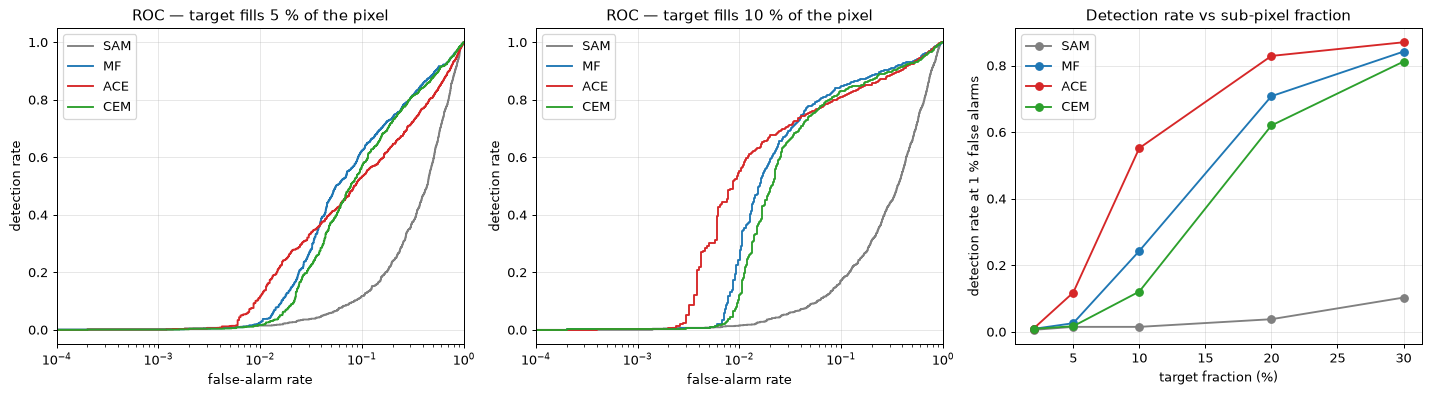

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
style = {"SAM": "0.5", "MF": "tab:blue", "ACE": "tab:red", "CEM": "tab:green"}
for ax, f in zip(axes[:2], (0.05, 0.1)):
    for name in style:
        fpr, tpr, _ = roc_data[(f, name)]
        ax.plot(fpr, tpr, color=style[name], label=name)
    ax.set_xscale("log"); ax.set_xlim(1e-4, 1)
    ax.set_xlabel("false-alarm rate"); ax.set_ylabel("detection rate")
    ax.set_title(f"ROC — target fills {f * 100:.0f} % of the pixel"); ax.grid(alpha=0.3); ax.legend()
for name in style:
    d = res[res.detector == name]
    axes[2].plot(d.fraction * 100, d.Pd_at_1pct_FA, "o-", color=style[name], label=name)
axes[2].set_xlabel("target fraction (%)"); axes[2].set_ylabel("detection rate at 1 % false alarms")
axes[2].set_title("Detection rate vs sub-pixel fraction"); axes[2].grid(alpha=0.3); axes[2].legend()
plt.tight_layout(); plt.show()

The statistical detectors find roofs that cover only part of a pixel: at 10 % fill, ACE detects roughly half of the
implanted targets at a 1 % false-alarm rate, while SAM detects almost none. ACE is the best detector at low
false-alarm rates; MF and CEM catch up at higher rates. The log-scaled false-alarm axis matters: operational detection needs very low false-alarm rates because a scene has
hundreds of thousands of background pixels.

⚠️ Implantation results are **optimistic**: linear mixing is assumed, there is no misregistration or adjacency
effect, and the implanted spectra come from the same park as the signature. Treat them as an upper bound and a way
to *compare* detectors and settings.

**Shrinkage matters.** Repeat the 5 % experiment for different values of λ:

In [15]:
f = 0.05
host = background[rng.choice(len(background), 1000, replace=False)]
implanted = (1 - f) * host + f * half2[rng.integers(0, len(half2), 1000)]
X = np.vstack([clean, implanted]); y = np.r_[np.zeros(len(clean)), np.ones(len(implanted))]
rows_l = []
for lam in (1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1):
    mu_l, Ci_l = background_stats(background, lam)
    rows_l.append(dict(lam=lam, MF=roc_auc_score(y, matched_filter(X, t_sig, mu_l, Ci_l)),
                       ACE=roc_auc_score(y, ace(X, t_sig, mu_l, Ci_l))))
pd.DataFrame(rows_l).set_index("lam").round(3)

,MF,ACE
lam,,
0.000001,0.678,0.597
0.000010,0.715,0.626
0.000100,0.780,0.680
0.001000,0.825,0.755
0.010000,0.821,0.740
0.100000,0.758,0.642


Too much shrinkage throws away the whitening that makes the detectors powerful; too little can over-fit noise
(especially when the background sample is small compared with the number of bands). In practice λ is tuned on
implanted targets like this, or the data are first reduced with PCA/MNF (notebook 13).

### 3.5 Running the detectors on the real scene

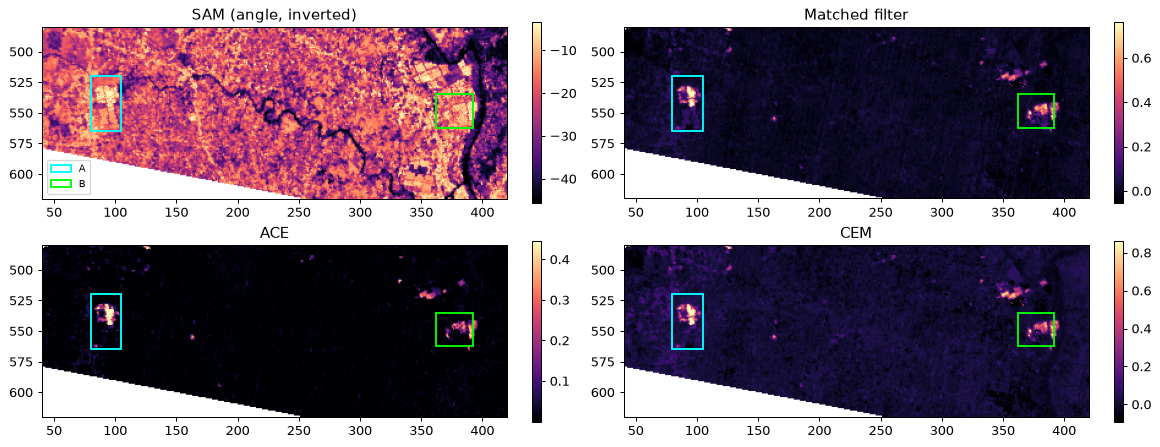

In [16]:
scores = {"SAM (angle, inverted)": -np.degrees(hu.spectral_angle(Xh, t_sig)),
          "Matched filter": matched_filter(Xh, t_sig, mu, Ci),
          "ACE": ace(Xh, t_sig, mu, Ci),
          "CEM": cem(Xh, t_sig, LAM)}
fig, axes = plt.subplots(2, 2, figsize=(13, 5))
for ax, (name, sc) in zip(axes.flat, scores.items()):
    img = hu.pixels_to_image(sc, h_mask)
    im = ax.imshow(img, cmap="magma", vmin=np.nanpercentile(img, 1), vmax=np.nanpercentile(img, 99.9), extent=h_ext)
    ax.add_patch(box_patch(PARK_A, "cyan", "A")); ax.add_patch(box_patch(PARK_B, "lime", "B"))
    ax.set_title(name); plt.colorbar(im, ax=ax, fraction=0.02)
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

SAM lights up large parts of the city (every bright, flat-spectrum surface is "similar" to a mixed roof pixel).
The matched filter, ACE and CEM suppress the background and highlight **park B** — and a few other blue-roofed
buildings — although the signature came only from park A. Faint vertical stripes in the MF and CEM maps are
**detector striping** of the pushbroom sensor: whitening amplifies tiny column-to-column calibration differences.

Finally, a detection map needs a threshold. ACE scores lie between 0 and 1, which makes thresholds transferable
between scenes. Below we mark pixels with ACE above the 99.8th percentile of the background scores (≈ 0.2 % false
alarms on background).

ACE threshold = 0.223; detected pixels: 301 (park A: 126, park B: 81)


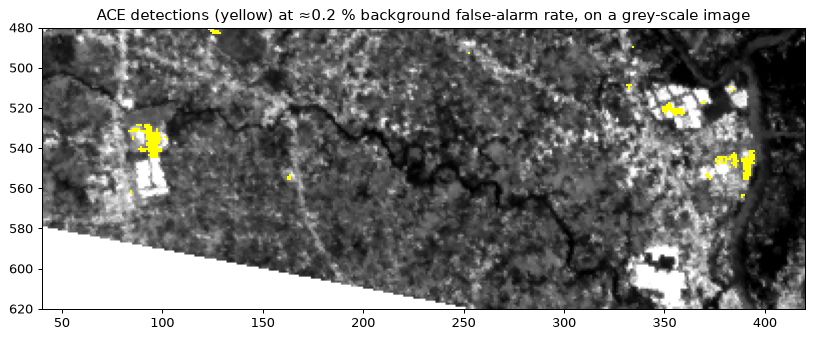

In [17]:
ace_bg = ace(background, t_sig, mu, Ci)
thr = np.percentile(ace_bg, 99.8)
det = hu.pixels_to_image((scores["ACE"] > thr).astype(float), h_mask)
print(f"ACE threshold = {thr:.3f}; detected pixels: {int(np.nansum(det))} "
      f"(park A: {int(np.nansum(det[r0:r1, c0:c1]))}, "
      f"park B: {int(np.nansum(det[PARK_B[0]-HW[0]:PARK_B[1]-HW[0], PARK_B[2]-HW[2]:PARK_B[3]-HW[2]]))})")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.imshow(hu.rgb_from_cube(h_cube, h_wl).mean(axis=2), cmap="gray", extent=h_ext)
ax.imshow(np.where(det == 1, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1, extent=h_ext, interpolation="nearest")
ax.set_title("ACE detections (yellow) at ≈0.2 % background false-alarm rate, on a grey-scale image")
plt.tight_layout(); plt.show()

---
## 4. Linear spectral unmixing

### 4.1 The linear mixing model
If the materials in a pixel are side by side (a "checkerboard" at sub-pixel scale), the measured spectrum is a
weighted sum of the pure spectra, the **endmembers** $\mathbf{e}_1\ldots\mathbf{e}_p$:

$$\mathbf{x} = \sum_{i=1}^{p} a_i\,\mathbf{e}_i + \mathbf{n}, \qquad a_i \ge 0 \;\;(\text{ANC}),\qquad \sum_i a_i = 1 \;\;(\text{ASC})$$

The abundances $a_i$ are the area fractions. Non-linear mixing (light bouncing between tree crowns, intimate mineral
mixtures) breaks this model — the residual tells us where.

Unmixing has two steps: (1) find the endmembers, (2) estimate the abundances.

We use the Jiquilisco Bay estuary in El Salvador: water, surf, sand bars, grassland, crops and mangroves.

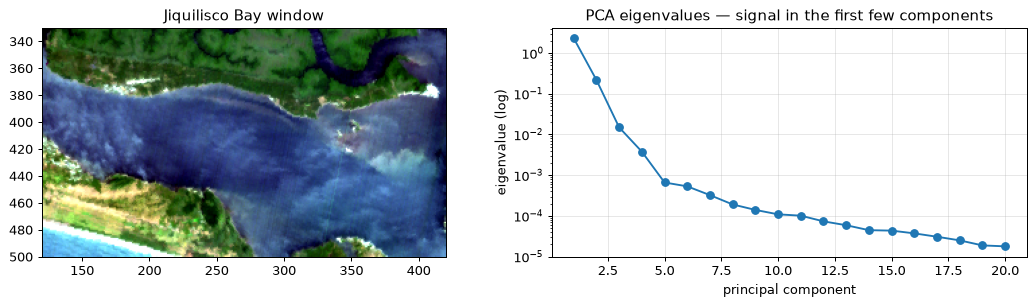

variance explained by the first 4 PCs: 99.89 %


In [18]:
salv = hu.get_scene("20250223_165546_32_4001")
UW = (330, 500, 120, 420)
u_cube, u_wl = salv.read_cube(UW)
u_ext = (UW[2], UW[3], UW[1], UW[0])
Xu, u_mask = hu.cube_to_pixels(u_cube)

# How many endmembers? Look at the PCA eigenvalue spectrum.
evals = np.linalg.eigvalsh(np.cov(Xu[::5], rowvar=False))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].imshow(hu.rgb_from_cube(u_cube, u_wl), extent=u_ext); axes[0].set_title("Jiquilisco Bay window")
axes[1].semilogy(np.arange(1, 21), evals[:20], "o-")
axes[1].set_xlabel("principal component"); axes[1].set_ylabel("eigenvalue (log)")
axes[1].set_title("PCA eigenvalues — signal in the first few components"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("variance explained by the first 4 PCs:", np.round(evals[:4].sum() / evals.sum() * 100, 2), "%")

With $p$ endmembers the data lie (approximately) in a $(p-1)$-dimensional simplex, so $p-1$ principal components
carry the signal. The eigenvalues flatten after a handful of components; we choose **p = 5** (try other values in
exercise 4). More formal estimators exist (virtual dimensionality, HySime).

### 4.2 Endmember extraction with N-FINDR
**N-FINDR** (Winter, 1999) assumes that the purest pixels are the vertices of the simplex that contains the data,
so it searches for the $p$ pixels that span the **largest volume**. The volume of the simplex with vertices
$\mathbf{y}_1\ldots\mathbf{y}_p$ in $p-1$ PCA dimensions is proportional to

$$V \propto \left|\det\begin{bmatrix}1 & \cdots & 1\\ \mathbf{y}_1 & \cdots & \mathbf{y}_p\end{bmatrix}\right|$$

Algorithm: start with random pixels; for each vertex, try replacing it with every candidate pixel and keep the
replacement that increases the volume most; repeat until nothing changes. Alternatives: **PPI** (pixel purity index,
Boardman 1993) and **VCA** (Nascimento & Bioucas-Dias, 2005).

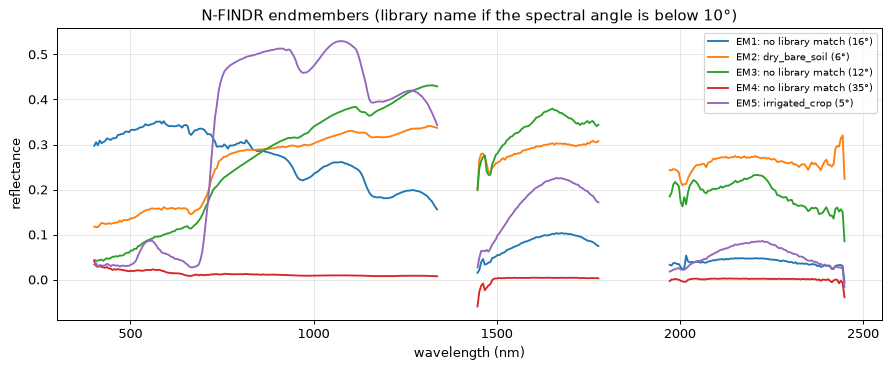

In [19]:
def nfindr(X, p, n_sample=6000, max_iter=10, seed=0):
    # Return p endmember spectra (p, bands) by maximising the simplex volume in PCA space.
    rng = np.random.default_rng(seed)
    Xs = X[rng.choice(len(X), min(n_sample, len(X)), replace=False)]
    mu = Xs.mean(axis=0)
    _, _, Vt = np.linalg.svd(Xs - mu, full_matrices=False)
    Y = (Xs - mu) @ Vt[: p - 1].T                        # (N, p-1)
    idx = list(rng.choice(len(Y), p, replace=False))
    M = np.vstack([np.ones(p), Y[idx].T])
    best = abs(np.linalg.det(M))
    for _ in range(max_iter):
        changed = False
        for i in range(p):
            trial = np.repeat(np.vstack([np.ones(p), Y[idx].T])[None], len(Y), axis=0)
            trial[:, 0, i] = 1.0
            trial[:, 1:, i] = Y                            # replace vertex i by every candidate
            vol = np.abs(np.linalg.det(trial))
            j = int(np.argmax(vol))
            if vol[j] > best * (1 + 1e-9):
                idx[i], best, changed = j, vol[j], True
        if not changed:
            break
    return Xs[idx]


P = 5
E = nfindr(Xu, P)
R_all, ok_all = library_on(u_wl, list(lib))
em_names = []
for e in E:
    ang = np.degrees(hu.spectral_angle(R_all[:, ok_all], e[ok_all]))
    best_name = list(lib)[int(np.argmin(ang))]
    hint = best_name if ang.min() < 10 else "no library match"
    em_names.append(f"EM{len(em_names) + 1}: {hint} ({ang.min():.0f}°)")

fig, ax = plt.subplots(figsize=(10, 4.2))
for e, n in zip(E, em_names):
    hu.plot_spectrum(ax, u_wl, e, label=n)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("N-FINDR endmembers (library name if the spectral angle is below 10°)")
plt.tight_layout(); plt.show()

The endmembers are the most *extreme* pixels, not necessarily the materials you care about: typical results are
bright surf or white sand, dark water, green vegetation, dry grass or soil. The nearest library match is only a hint —
look at the spectra. A flat, bright spectrum with a water-like drop in the NIR is breaking surf ("whitewater"),
which is not in our library.

### 4.3 Abundance estimation: LS, NNLS and FCLS
- **Unconstrained least squares**: $\hat{\mathbf{a}} = (\mathbf{E}^\top\mathbf{E})^{-1}\mathbf{E}^\top\mathbf{x}$ — fast, but gives
  negative fractions.
- **NNLS**: least squares with $a_i \ge 0$ (`scipy.optimize.nnls`).
- **FCLS** (Heinz & Chang, 2001): non-negative *and* sum-to-one. A classic trick implements it with NNLS by adding
  one extra "band" of value $\delta$ to every endmember and to the pixel: the solver must then make
  $\delta\sum a_i \approx \delta$. Larger $\delta$ enforces the sum more strictly.

In [20]:
Et = E.T                                                   # (bands, p)
A_ls = np.linalg.lstsq(Et, Xu.T, rcond=None)[0].T
A_nnls = np.array([nnls(Et, x)[0] for x in Xu])
delta = 10.0
E_aug = np.vstack([Et, delta * np.ones(P)])
A_fcls = np.array([nnls(E_aug, np.r_[x, delta])[0] for x in Xu])

summary = pd.DataFrame({
    "method": ["LS", "NNLS", "FCLS"],
    "% pixels with a negative fraction": [(A.min(1) < -0.01).mean() * 100 for A in (A_ls, A_nnls, A_fcls)],
    "median sum of fractions": [np.median(A.sum(1)) for A in (A_ls, A_nnls, A_fcls)],
    "median RMSE (reflectance)": [np.median(np.sqrt(((Xu - A @ E) ** 2).mean(1))) for A in (A_ls, A_nnls, A_fcls)],
})
summary.round(4)

,method,% pixels with a negative fraction,median sum of fractions,median RMSE (reflectance)
0,LS,94.202,0.8888,0.0031
1,NNLS,0.000,0.9398,0.0065
2,FCLS,0.000,1.0000,0.0065


Unconstrained least squares has the smallest residual, but almost every pixel gets at least one physically impossible
negative fraction — it "explains" the spectrum with arbitrary positive and negative combinations. NNLS removes the
negative fractions; FCLS additionally makes the fractions add up to one, so they can be read as area percentages.

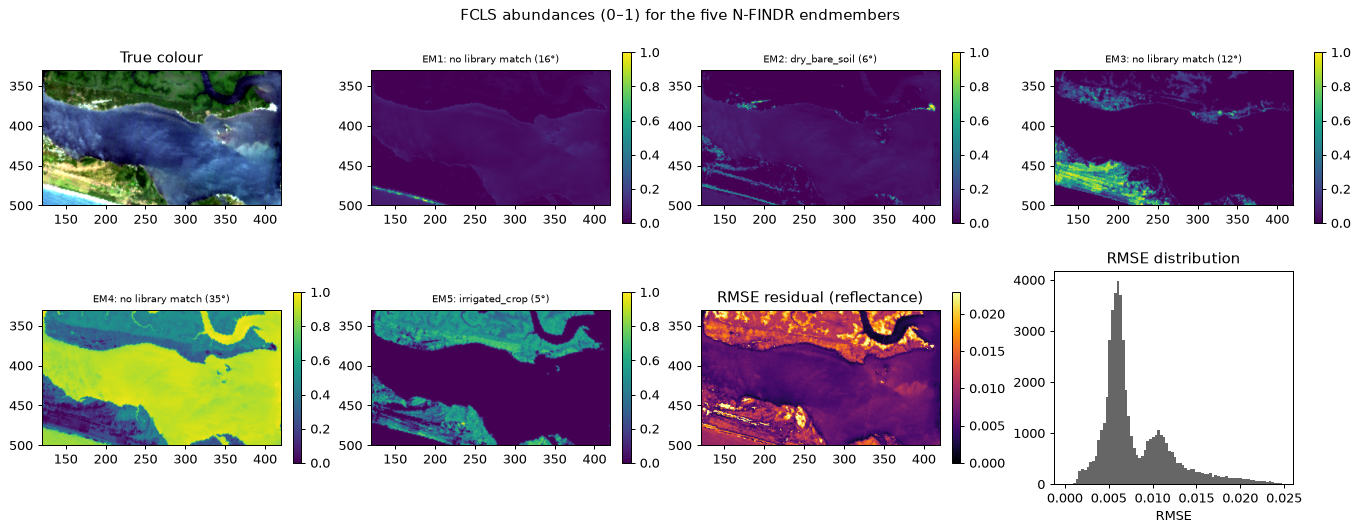

In [21]:
rmse = np.sqrt(((Xu - A_fcls @ E) ** 2).mean(axis=1))
fig, axes = plt.subplots(2, 4, figsize=(15, 5.8), constrained_layout=True)
axes[0, 0].imshow(hu.rgb_from_cube(u_cube, u_wl), extent=u_ext); axes[0, 0].set_title("True colour")
for i, ax in enumerate(axes.flat[1:P + 1]):
    im = ax.imshow(hu.pixels_to_image(A_fcls[:, i], u_mask), cmap="viridis", vmin=0, vmax=1, extent=u_ext)
    ax.set_title(em_names[i], fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8)
ax = axes.flat[P + 1]
im = ax.imshow(hu.pixels_to_image(rmse, u_mask), cmap="inferno", vmin=0, vmax=np.percentile(rmse, 99), extent=u_ext)
ax.set_title("RMSE residual (reflectance)"); fig.colorbar(im, ax=ax, shrink=0.8)
axes.flat[P + 2].hist(rmse, bins=80, range=(0, np.percentile(rmse, 99.5)), color="0.4")
axes.flat[P + 2].set_title("RMSE distribution"); axes.flat[P + 2].set_xlabel("RMSE")
fig.suptitle("FCLS abundances (0–1) for the five N-FINDR endmembers")
plt.show()

The residual map is a diagnostic: where the RMSE is high, the pixel contains a material that none of the endmembers
represents, or mixing is non-linear. Here the highest residuals are on the barrier island in the south-west — a
patchwork of beach sand, palms, grass and fields that five endmembers cannot represent — and in the mangrove
forest north of the estuary, where a single green-crop endmember does not match the shape of mangrove canopies
(canopies also mix light non-linearly). Remedies: more endmembers, **multiple endmember** unmixing (MESMA, Roberts et al., 1998) or non-linear
models.

---
## 5. 🛢️ Box: methane — the matched filter at work

Tanager was designed with methane in mind. CH₄ absorbs in several narrow lines between **2200 and 2400 nm**. The
standard retrieval (Thompson et al., 2015; the MAG1C algorithm of Foote et al., 2020; Carbon Mapper's operational
pipeline) is exactly the matched filter of section 3, applied to **at-sensor radiance** with a *unit absorption
spectrum* as the target:

$$\mathbf{t} = \boldsymbol\mu \odot \mathbf{k}, \qquad \hat{\alpha} = \frac{(\mathbf{x}-\boldsymbol\mu)^\top\boldsymbol\Sigma^{-1}\mathbf{t}}{\mathbf{t}^\top\boldsymbol\Sigma^{-1}\mathbf{t}}$$

where $\mathbf{k}$ is the change in log-radiance per unit of CH₄ enhancement (ppm·m), computed with a radiative
transfer model for the scene's sun and view geometry, and $\hat\alpha$ is the methane enhancement per pixel.

Why radiance and not surface reflectance? Atmospheric correction treats gas absorption as part of the atmosphere,
so plume absorption is partly *removed* from the reflectance product. The **MBSI / plume proxy** of notebook 03 uses
reflectance band ratios; it is a useful teaching tool but responds to **surface materials** with absorption features
near 2300 nm just as much as to methane. Here is the evidence, using notebook 03's band choice (references 2250 and
2380 nm, absorption 2305 and 2345 nm) on the library spectra, which contain no methane plumes:

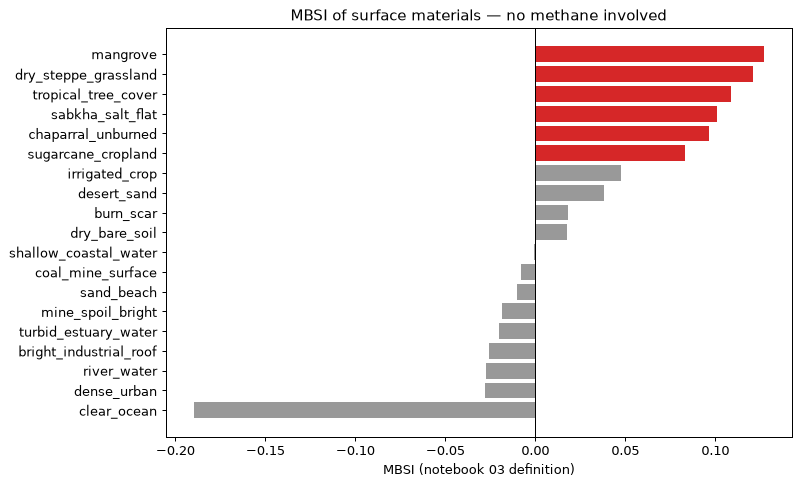

In [22]:
def mbsi(wl, s):
    # notebook 03: MBSI = (R_ref1 + R_ref2) / (2 · R_abs) − 1 with R_abs = mean of the two absorption bands
    g = lambda nm: s[hu.band_index(wl, nm)]
    r_abs = (g(2305) + g(2345)) / 2
    return (g(2250) + g(2380)) / (2 * r_abs) - 1

vals = pd.Series({n: mbsi(lib_wl, lib[n]) for n in lib}).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(vals.index, vals.values, color=["tab:red" if v > 0.05 else "0.6" for v in vals.values])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("MBSI (notebook 03 definition)"); ax.set_title("MBSI of surface materials — no methane involved")
plt.tight_layout(); plt.show()

Vegetation (leaf water, cellulose and lignin absorb near 2300 nm) and the carbonate/sulphate-rich sabkha give clearly
positive MBSI without any methane. A real plume adds only a few percent of absorption, so surface variability swamps it. The matched filter
solves this by modelling the background covariance — surface variability is "whitened away".

**Planet's GHG-plumes collection ships the operational product.** Items in the `GHG-plumes` STAC collection include:
- `ortho_radiance_hdf5` — the radiance needed for a matched-filter retrieval,
- `ortho_ql_ch4` — a **methane quick-look** COG from Carbon Mapper (uint8 "concentration index", qualitative),
- `ql_ch4_json` — plume origins as GeoJSON points with emission rate (kg/h), uncertainty and wind information.

The cell below (🌐 **needs internet**, ~10 s) shows them for a scene in Deir ez-Zor, Syria with 12 detected plumes.
Our local Korba scene lists plume IDs in its metadata, but its quick-look layer and plume file are empty.

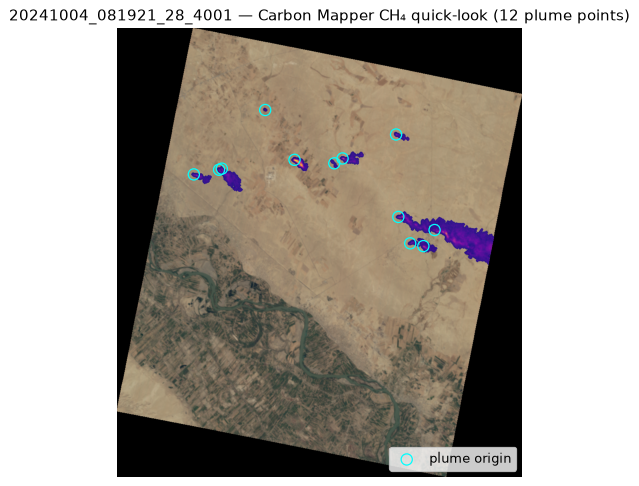

                       plume_id  emission_kg_per_h  uncertainty_kg_per_h  wind_speed_avg plume_quality
20241004_081910_00_4001_strip_A              446.0                  85.8             2.5          good
20241004_081910_00_4001_strip_B              947.1                 169.7             2.1          good
20241004_081910_00_4001_strip_C              173.8                  62.6             2.1  questionable
20241004_081910_00_4001_strip_D             3188.9                 389.7             2.0  questionable
20241004_081910_00_4001_strip_E             1150.3                 178.6             2.0  questionable
20241004_081910_00_4001_strip_F             1151.9                 151.1             2.0  questionable
20241004_081910_00_4001_strip_G              594.9                  78.3             2.0          good
20241004_081910_00_4001_strip_H             1231.1                 236.8             2.1          good
20241004_081910_00_4001_strip_I             1373.7                 262.7 

In [23]:
# 🌐 Online cell — skipped gracefully if there is no internet connection.
try:
    import requests, rasterio
    from rasterio.warp import transform as warp_points
    item = hu.fetch_item("20241004_081921_28_4001", "GHG-plumes")
    with rasterio.open(item["assets"]["ortho_ql_ch4"]["href"]) as src:
        ch4 = src.read(1).astype(float)
        ch4_crs, ch4_transform = src.crs, src.transform
    with rasterio.open(item["assets"]["ortho_visual"]["href"]) as src:
        vis = src.read([1, 2, 3], out_shape=(3,) + ch4.shape).transpose(1, 2, 0)
    plumes = requests.get(item["assets"]["ql_ch4_json"]["href"], timeout=60).json()["features"]
    ch4[ch4 == 0] = np.nan

    # plume origins: lon/lat → map coordinates → pixel (col, row) of the quick-look grid
    lon = [p["geometry"]["coordinates"][0] for p in plumes]
    lat = [p["geometry"]["coordinates"][1] for p in plumes]
    xs, ys = warp_points("EPSG:4326", ch4_crs, lon, lat)
    cols, rows_p = ~ch4_transform * (np.array(xs), np.array(ys))

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(vis)
    ax.imshow(ch4, cmap="plasma", alpha=0.9)
    ax.scatter(cols, rows_p, s=80, facecolors="none", edgecolors="cyan", label="plume origin")
    ax.set_title(f"{item['id']} — Carbon Mapper CH₄ quick-look ({len(plumes)} plume points)")
    ax.legend(loc="lower right"); ax.axis("off"); plt.tight_layout(); plt.show()
    print(pd.DataFrame([p["properties"] for p in plumes])[
        ["plume_id", "emission", "emission_uncertainty", "wind_speed_avg", "plume_quality"]]
          .rename(columns={"emission": "emission_kg_per_h", "emission_uncertainty": "uncertainty_kg_per_h"})
          .round(1).to_string(index=False))
except Exception as err:
    print("Online example skipped:", type(err).__name__, err)

---
## ✏️ Your turn

**1. Per-class SAM thresholds.** For the Korba window, plot the histogram of the angle to `coal_mine_surface` and to
`mine_spoil_bright` *for the pixels assigned to those classes*. Choose a separate threshold per class and recompute
the map. How much of the mine is now classified?

<details><summary>Hint</summary>Use <code>rule[best_class == i, i]</code> for class <i>i</i>. Pick the threshold at a
valley of the histogram or at a percentile (e.g. 95th) of the class's angles.</details>
<details><summary>Solution</summary>

```python
thr = {0: np.radians(8), 1: np.radians(10)}           # coal, spoil
cls = best_class.astype(float)
reject = np.zeros_like(best, bool)
for i in range(len(korba_refs)):
    t = thr.get(i, np.radians(12))
    reject |= (best_class == i) & (best > t)
cls[reject] = np.nan
plt.imshow(hu.pixels_to_image(cls, k_mask), cmap=cmap, vmin=-0.5, vmax=6.5, interpolation="nearest")
print("unclassified:", reject.mean())
```
</details>

**2. White roofs.** Use the library spectrum `bright_industrial_roof` as the target and run ACE on the Ho Chi Minh
City window. Compare the detections with the red cloud-mask outline — what does this tell you about the beta cloud
mask?

<details><summary>Hint</summary>Interpolate the library spectrum onto <code>h_wl</code>; drop bands where it is NaN from
both the target and the pixels, and recompute the background statistics on those bands.</details>
<details><summary>Solution</summary>

```python
t_white = np.interp(h_wl, lib_wl, lib["bright_industrial_roof"])
okb = np.isfinite(t_white)
mu_w, Ci_w = background_stats(background[:, okb], 1e-3)
ace_w = ace(Xh[:, okb], t_white[okb], mu_w, Ci_w)
plt.imshow(hu.pixels_to_image(ace_w, h_mask), vmax=np.percentile(ace_w, 99.9))
plt.contour(cloud_flag, levels=[0.5], colors="red")
```
The white roofs that ACE finds coincide with pixels flagged as "cloud": the beta mask confuses bright roofs
with clouds.
</details>

**3. Harder targets.** Run the implantation experiment with $f = 0.01$ and $f = 0.02$. Which detector wins? Then
repeat with the signature estimated from only **5** roof pixels. What happens and why?

<details><summary>Hint</summary>A signature from few pixels is noisy; the whitened noise direction then no longer
matches the implanted targets. Compare MF (which uses the signature magnitude) with ACE.</details>

**4. Number of endmembers.** Re-run N-FINDR and FCLS with P = 3, 4, 7. Plot the median RMSE against P. Which new
materials appear as P grows, and where does the residual drop?

<details><summary>Solution</summary>

```python
for p in (3, 4, 5, 7):
    Ep = nfindr(Xu, p)
    Ea = np.vstack([Ep.T, delta * np.ones(p)])
    A = np.array([nnls(Ea, np.r_[x, delta])[0] for x in Xu[::10]])
    print(p, np.median(np.sqrt(((Xu[::10] - A @ Ep) ** 2).mean(1))))
```
</details>

**5. A clay map for the whole mine.** Compute the 2205 nm band depth for the entire Korba scene using
`korba.read_cube(stride=2)` and overlay pixels with depth > 0.06 on a true-colour image. Where else, besides the
spoil heaps, are clays exposed?

---
## Key takeaways
- **SAM / SID** compare spectral *shape* and ignore brightness — good for whole-pixel material matching with a
  library; thresholds and library completeness control the result.
- **Continuum removal** isolates diagnostic absorption features (e.g. Al–OH clays at 2200 nm) and is the basis of
  mineral mapping.
- **Detectors (MF, ACE, CEM)** use background statistics to find **sub-pixel** targets that SAM misses. Covariance
  estimation (shrinkage, background sample) is the critical design choice.
- **Implantation experiments + ROC curves** are an honest way to compare detectors when ground truth is scarce — but
  they are an upper bound.
- **Unmixing** turns a pixel into fractions; the **residual map** tells you where the linear model or the endmember
  set fails.
- Methane retrievals are matched filters on radiance; reflectance band ratios are proxies that surface materials can
  fool.

**For your project:** if your theme involves specific materials (plastics, roofs, minerals, algae, methane), plan a
detection or unmixing step and an implantation or reference-data test to prove it works.

**References:** Kruse et al. (1993) *Remote Sens. Environ.* 44; Chang (2000) *IEEE TIT* 46; Clark & Roush (1984)
*JGR* 89; Harsanyi (1993) PhD thesis; Kraut & Scharf (1999) *IEEE TSP* 47; Manolakis & Shaw (2002) *IEEE Signal
Process. Mag.* 19; Winter (1999) *Proc. SPIE* 3753; Nascimento & Bioucas-Dias (2005) *IEEE TGRS* 43; Heinz & Chang
(2001) *IEEE TGRS* 39; Roberts et al. (1998) *Remote Sens. Environ.* 65; Thompson et al. (2015) *AMT* 8;
Foote et al. (2020) *IEEE TGRS* 58.

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · Methane quick-look & plume data: Carbon Mapper via Planet STAC ·
> Reference library labels: ESA WorldCover 2021 v200 — CC-BY 4.0